# Maxwell 2D photonic-crystal waveguide bend (90°)
A square lattice of dielectric rods with an L-shaped path of rods removed: the
missing rods carve a line-defect waveguide that turns a sharp 90° corner. Light
injected into the channel at an in-gap wavelength is guided along it and around the
corner -- it *cannot* leak
into the surrounding crystal, because that is the bandgap (there are no bulk
modes for it to escape into).

Why this is the famous result (Mekis, Fan, ... Joannopoulos, Phys. Rev. Lett.
77, 3787 (1996)): a conventional dielectric waveguide radiates most of its power
away at a sharp 90° bend. A photonic-crystal waveguide can
turn the same corner with near-100% transmission, because the bandgap forbids
radiation -- the light has nowhere to go but around the bend. There is no ray-
optics account of this; it is pure bandgap confinement.

Geometry:
  * square lattice of circular dielectric rods, n = 3.4 in air, r = 0.2 a,
    a = 0.4 μm;
  * a line-defect waveguide made by REMOVING one row of rods (horizontal arm)
    and one column of rods (vertical arm), meeting at a 90° corner;
  * 2D via a one-pixel-thick, periodic-z domain; TM polarization (E along the
    rods, z-polarized) -- the polarization with the gap.

This is a SINGLE simulation at one wavelength (no sweep). The operating wavelength
is chosen mid-gap (a/λ ≈ 0.34), where the defect waveguide supports a guided mode;
`operating_wavelength` sets where in the gap the light sits.

Size: 1.000 Mvoxel including boundaries, 0.052 GB of memory (service estimate).

Reuses ``wsutils.create_source.gaussian_beam`` for a narrow mode-launching
source inside the channel; the rod lattice is built directly with NumPy.

In [1]:
import numpy as np
from time import time

from wsutils.create_source import gaussian_beam
from wavesimpro import configure, simulate
from wsutils import output_dir, plot_computed

NAME = "mx_pc_waveguide_bend"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

# Crystal parameters
pixel_size = 0.02  # Pixel size in micrometer (μm); ~8 px/rod, ~59 px/λ
lattice_constant = 0.4  # Lattice constant a, in micrometer (μm)
rod_radius = 0.2 * lattice_constant  # Canonical r = 0.2 a
rod_index = 3.4  # Silicon-like refractive index
operating_wavelength = 1.18  # Mid-gap (a/λ ≈ 0.34); the defect waveguide guides here

# Lattice extent (number of rods) and origin
n_rods_x = 24
n_rods_y = 24
rod_origin = 0.4  # x, y of the first rod (μm)

# L-shaped channel, defined on the lattice index grid (i along x, j along y):
#   horizontal arm = remove row  j = wg_row,    for i = 0 .. corner_i
#   vertical arm   = remove column i = corner_i, for j = wg_row .. end
wg_row = 6  # the guided row (horizontal arm)
corner_i = 14  # column index of the 90° corner / vertical arm

# Domain: X = propagation in / Y = turn down; Z = (thin, periodic -> 2D)
sim_size = np.array([10.0, 10.0])  # (x, y) simulation size in micrometer (μm)
n_size = (sim_size / pixel_size).astype(int)
nx, ny = int(n_size[0]), int(n_size[1])

# Handy physical coordinates of the channel (for the source)
wg_y = rod_origin + wg_row * lattice_constant  # y of the horizontal arm
corner_x = rod_origin + corner_i * lattice_constant  # x of the corner / vertical arm


def build_bent_waveguide():
    """Square rod lattice with an L-shaped row/column of rods removed; returns
    permittivity (n²) as a (nx, ny, 1) array (one pixel thick in z)."""
    x = (np.arange(nx) * pixel_size)[:, None]
    y = (np.arange(ny) * pixel_size)[None, :]
    refractive_index = np.ones((nx, ny), dtype=np.complex64)  # background air

    n_removed = 0
    for i in range(n_rods_x):
        for j in range(n_rods_y):
            on_horizontal_arm = (j == wg_row) and (i <= corner_i)
            on_vertical_arm = (i == corner_i) and (j >= wg_row)
            if on_horizontal_arm or on_vertical_arm:
                n_removed += 1
                continue  # leave this lattice site empty -> the waveguide channel
            cx = rod_origin + i * lattice_constant
            cy = rod_origin + j * lattice_constant
            refractive_index[(x - cx) ** 2 + (y - cy) ** 2 < rod_radius**2] = rod_index

    print(f"Photonic crystal: {n_rods_x}x{n_rods_y} lattice, n={rod_index}, r={rod_radius:.3f} μm, a={lattice_constant} μm")
    print(f"L-waveguide: horizontal arm at y={wg_y:.2f} μm, vertical arm at x={corner_x:.2f} μm ({n_removed} rods removed)")
    return (refractive_index**2)[..., None]


permittivity = build_bent_waveguide()

# Narrow z-polarized source INSIDE the horizontal channel near its left opening,
# spanning ~one lattice period across the channel so it couples to the guided
# mode (TM: E along the rods).
source_values, source_position = gaussian_beam(
    shape=0.5,  # source width across the channel, in micrometer (μm)
    origin="center",
    position=[2, rod_origin + 1.5 * lattice_constant, wg_y, 0],  # z-pol, just inside the channel
    source_plane="y",
    pixel_size=pixel_size,
    waist=0.17,  # μm — narrower than the channel
)

Photonic crystal: 24x24 lattice, n=3.4, r=0.080 μm, a=0.4 μm
L-waveguide: horizontal arm at y=2.80 μm, vertical arm at x=6.00 μm (32 rods removed)


### Run the simulation

Running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : dc799858-352d-4f97-b626-9ab0c8b116ac
  Version   : f51b65c4-6d76-49c2-9d9b-dde7d1006909
  Command   : 5088c427-e7d7-48ba-9ebb-876df4f9a4e8
  Mode      : Maxwell (vectorial)
  Domain    : 500x500x1 voxels  lambda=1.18 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 51.4 s; Iterations 12775


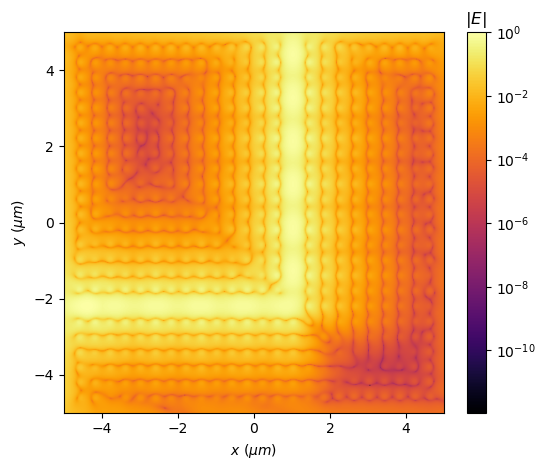

In [2]:
print("Running simulation...")
start = time()
u, iterations, residual_norm = simulate(
    permittivity=permittivity,
    sources=[(source_values, source_position)],
    wavelength=operating_wavelength,
    pixel_size=pixel_size,
    boundary_width=5.0,  # Absorbing boundary width, μm (≈4 λ)
    periodic=(False, False, True),  # periodic in z -> infinite rods (2D)
)
print(f"Time {time() - start:.1f} s; Iterations {iterations}")

# E_z field as a 2D (nx, ny) slice
ez = u[2]
if ez.ndim == 3:
    ez = ez[:, :, ez.shape[2] // 2]

# Light guided in along the horizontal arm, turning the 90° corner, and exiting
# down the vertical arm -- bright in the channel, dark in the bulk crystal (the
# bandgap forbids it from leaking sideways).
# save=True also writes <NAME>.png and .pdf to OUTPUT_DIR.
plot_computed(ez, pixel_size, log=True, save=True, filename=f"{OUTPUT_DIR}/{NAME}")